# Data Preprocessing
- Preprocessing the data with machin learning pipeline
- create a pickle file

# 1. Bussiness case:- Based the given feature find the person the get heart disease or not

In [159]:
# import requiered libreary
# interact with data
import numpy as np
import pandas as pd
# visualized data
import seaborn as sns
import matplotlib.pyplot as plt
# import waranings
import warnings
warnings.filterwarnings('ignore')

In [160]:
# data preprocessing
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,OrdinalEncoder,StandardScaler

In [161]:
# preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

In [162]:
# load the data 
df=pd.read_csv('heart.csv')

# 2. Domain Analysis

Domain Analysis of the Heart Disease Dataset

Your heart.csv dataset belongs to the Healthcare / Medical Data Analytics domain, specifically heart disease prediction using patient health information.

The dataset contains 918 records and 12 columns. Each record represents a patient's health measurements and clinical characteristics, and the target column indicates whether heart disease is present.

1. __Domain overview__:-

- Main domain: Healthcare and medical diagnosis

- Subdomain: Cardiovascular disease analysis

- Application: Machine learning classification and risk assessment

- Objective: Identify patterns in patient characteristics associated with heart disease.

- Target/output column: HeartDisease

- Problem type: Binary classification

- What is the dataset used for?

The dataset can be used to train a machine learning model that learns relationships between a patient's age, blood pressure, cholesterol, chest pain, exercise response, ECG measurements, and heart disease status.

The model's goal is to predict one of two classes:

- HeartDisease = 1: Heart disease is indicated in the dataset.

- HeartDisease = 0: Heart disease is not indicated in the dataset.

This is a dataset for analytical and predictive purposes, not a substitute for medical diagnosis.

2. __Domain analysis of every column__:-

The columns can be grouped into demographic information, clinical measurements, symptoms, diagnostic indicators, and the target variable.

    a Age__:-

Data type: Integer · Unit: Years

Represents the patient's age.

Domain meaning: Age is a demographic risk factor because cardiovascular disease risk often increases with age.

__Relation to target__: Analyze whether heart disease is more common among older patients in this dataset.

    b Sex__:-

Data type: Categorical · Values: M, F

Represents the patient's recorded sex.

Domain meaning: Used to examine differences in heart disease patterns between recorded sex groups.

__Relation to target__: Compare the proportion of patients with heart disease in each group. Differences in this dataset do not establish causation.

    c ChestPainType__:-

Data type: Categorical · Four categories

Describes the type of chest pain recorded for the patient.

          Value         |          Meaning


          TA                       Typical angina

	
         ATA                      Atypical angina
                

          NAP                      Non-anginal pain


         ASY                      Asymptomatic

	
__Relation to target__: Check which chest pain categories have higher proportions of positive heart disease records.

    d RestingBP__:-

Data type: Integer · Unit: mmHg

The patient's resting blood pressure.

Domain meaning: Blood pressure is an important cardiovascular health measurement.

__Relation to target__: Examine whether blood pressure levels differ between patients with and without heart disease.

Data-quality note: A value of 0 appears in this column's observed range, so it should be checked as a potentially invalid measurement.

    e Cholesterol__:-

Data type: Integer · Typically measured in mg/dL

Represents the recorded serum cholesterol measurement.

Domain meaning: Cholesterol is relevant to cardiovascular health and long-term heart disease risk.

__Relation to target__: Compare cholesterol distributions for the two target classes.

Data-quality note: Zero values appear in this column. Verify whether they represent missing or unrecorded measurements before using the data.

    f FastingBS__:-

Data type: Binary numeric · Values: 0, 1

Indicates whether fasting blood sugar is above the dataset's threshold of 120 mg/dL.

        Value                       Meaning

	     0                       Fasting blood sugar at or below 120 mg/dL

	
         1                       Fasting blood sugar above 120 mg/dL
         
__Relation to target__: Check whether the heart disease rate differs between these two groups.

    g RestingECG__:-

Data type: Categorical · Three categories

Describes the patient's resting electrocardiogram (ECG) results.

         Value                   Meaning

	
         Normal                  Normal resting ECG

	
         ST                      ST-T wave abnormality

	
         LVH                     Left ventricular hypertrophy

	
__Relation to target__: Analyze whether recorded ECG categories are associated with different heart disease rates.

    h MaxHR__:-

Data type: Integer · Unit: Beats per minute (bpm)

Represents the maximum heart rate achieved during the recorded exercise test.

Domain meaning: Exercise heart rate can provide information about cardiovascular response to physical activity.

__Relation to target__: Compare maximum heart rates in positive and negative heart disease records.

    i ExerciseAngina__:-

Data type: Categorical · Values: Y, N

Indicates whether angina (chest pain or discomfort) occurred during exercise.

        Value                    Meaning
 
        Y                        Exercise-induced angina present

        N                        Exercise-induced angina absent

__Relation to target__: Investigate whether patients with exercise-induced angina have a higher proportion of positive heart disease records.

    j Oldpeak__:-

Data type: Decimal · Unit: Typically mm

Represents ST-segment depression induced by exercise relative to rest.

Domain meaning: This ECG measurement can help assess the heart's response to exercise.

__Relation to target__: Study whether different Oldpeak values are associated with different heart disease rates.

    k ST_Slope__:-

Data type: Categorical · Three categories

Describes the slope of the peak exercise ST segment.

        Value                       Meaning

        Up                          Upsloping

        Flat                        Flat

        Down                        Downsloping

	
__Relation to target__: Compare heart disease prevalence across the three ST slope categories.

    l HeartDisease__:-

Data type: Integer · Binary output variable

This is the target column that the machine learning model attempts to predict.

Value                   Meaning

0                       Heart disease not indicated

1                       Heart disease indicated

__Domain meaning__: Represents the outcome or class label for each patient.

__Relation to other columns__: All 11 remaining columns can be examined as potential predictors of this outcome.

3. What is the relationship between the columns?

The dataset's central relationship is between patient characteristics and the HeartDisease outcome.

Important relationships to investigate

    Column relationship |What you can analyze
    
    Age → HeartDisease  |Whether disease prevalence differs by age group|

    Sex → HeartDisease  |Differences in prevalence between recorded sex groups

    ChestPainType →  |Which chest pain categories have higher disease rates
    HeartDisease

    RestingBP →  |Whether resting blood pressure is associated with the outcome
    HeartDisease

    Cholesterol → |Differences in cholesterol measurements by outcome
    HeartDisease

    FastingBS →|Whether elevated fasting blood sugar is associated with outcome
    HeartDisease

    RestingECG → |Association between ECG categories and the outcome
    HeartDisease

    MaxHR → HeartDisease |Whether exercise heart rate differs by outcome

    ExerciseAngina →HeartDisease|Association between exercise-induced angina                                    and disease status 

    Oldpeak → HeartDisease |Whether ST depression differs by outcome

    S |T_Slope → HeartDisease |Association between ST slope categories and                                    disease status

These are hypotheses to investigate in the dataset; their actual strength and direction should be established through statistical analysis.    

4. Final conclusion__:-
Dataset is a supervised machine learning dataset for binary heart disease classification.
    - Input variables: 11 demographic, symptom, clinical measurement, and            diagnostic columns.
    - Output variable: HeartDisease.
    - Primary relationship: How the recorded patient characteristics are             associated with the heart disease label.
    - Possible applications: Exploratory data analysis, medical data mining,         classification models, and research into cardiovascular risk indicators.

The next useful step is to calculate the actual column-by-column relationships with HeartDisease, using group-wise disease rates, correlation analysis for numeric variables, and categorical association tests. That will show which relationships are strongest in your specific dataset rather than assuming them from medical theory alone.

# 3. Basic Check

In [163]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


## insigts:
- there is no null value in the columns of the dataset

In [164]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [165]:
df.describe(include="O")

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


## Spperate int,floatand categorical columns

In [166]:
num_col=df.select_dtypes('number').columns
num_col

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease'],
      dtype='str')

In [167]:
cat_col=df.select_dtypes('str').columns

# 4. EDA (Exploratory Data Analysis)

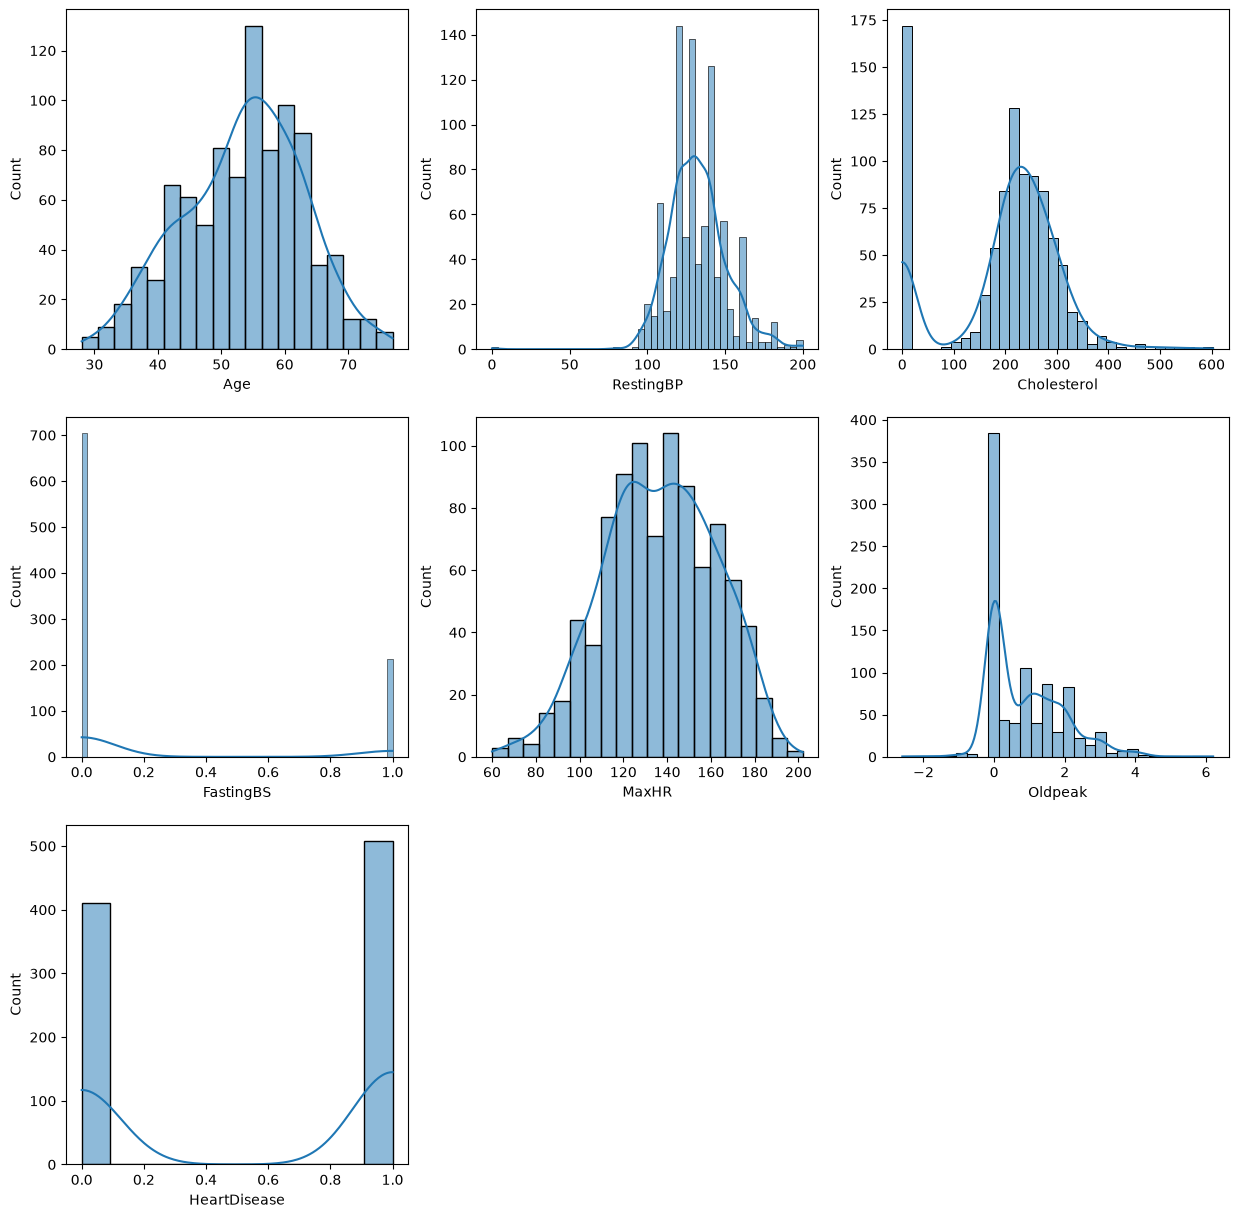

In [168]:
plt.figure(figsize=(15,15))
for i,j in enumerate(df.select_dtypes('number'),1):
    plt.subplot(3,3,i)
    sns.histplot(df[j],kde=True)

In [169]:
abc=np.log(df.MaxHR)

<Axes: xlabel='MaxHR', ylabel='Count'>

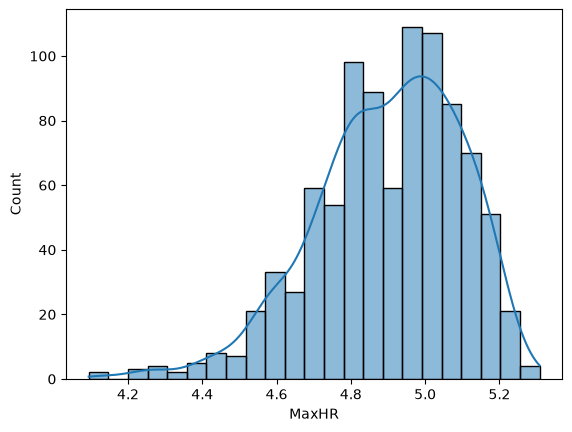

In [170]:
sns.histplot(x=abc,kde=True)

In [171]:
Abc=np.sqrt(df.MaxHR)

<Axes: xlabel='MaxHR', ylabel='Count'>

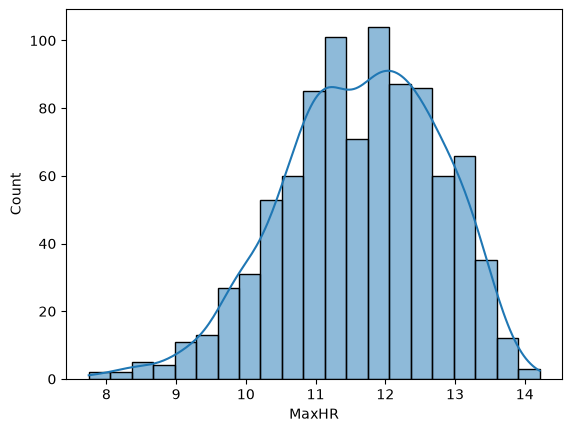

In [172]:
sns.histplot(x=Abc,kde=True)

In [173]:
abc=np.log(df.Oldpeak)

<Axes: xlabel='Oldpeak', ylabel='Count'>

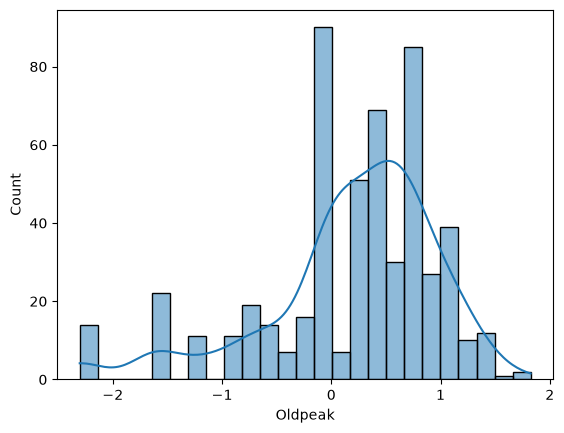

In [174]:
sns.histplot(x=abc,kde=True)

In [175]:
xyz=np.reciprocal(df.Oldpeak)

<Axes: xlabel='Oldpeak', ylabel='Count'>

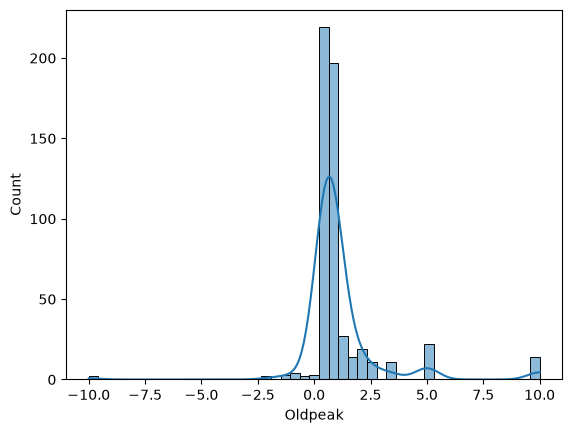

In [176]:
sns.histplot(x=xyz,kde=True)

- find the outliner in the data set

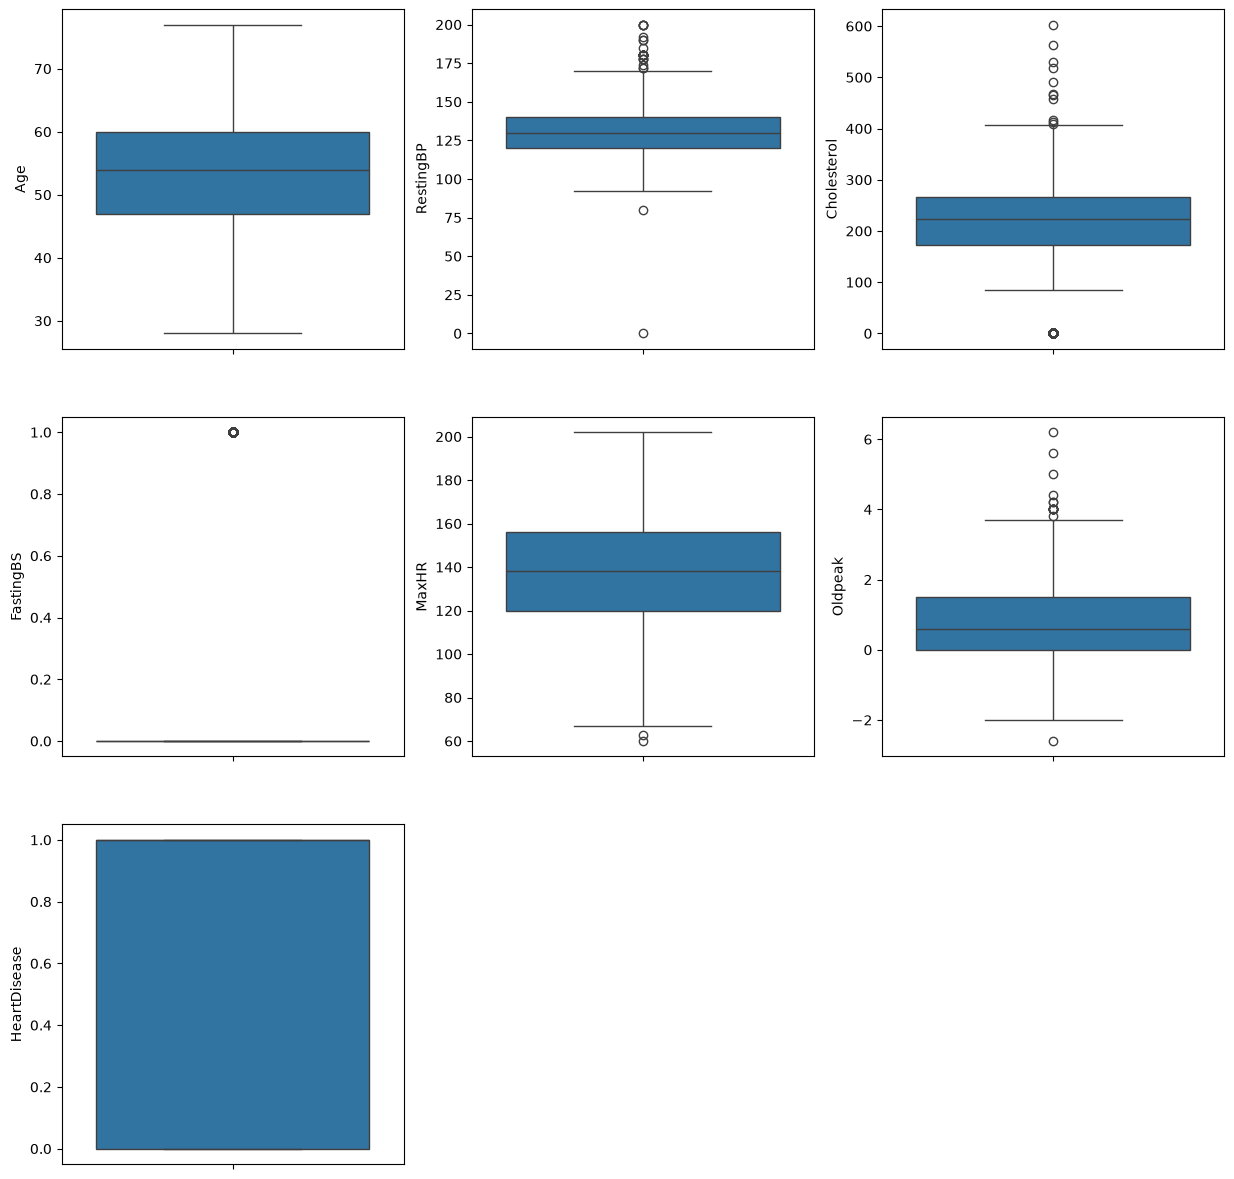

In [177]:
plt.figure(figsize=(15,15))
for i,j in enumerate(df.select_dtypes('number'),1):
    plt.subplot(3,3,i)
    sns.boxplot(df[j])

- Insighta:
    - in this data set __Resting BP__,__cholesterol__,__Oldpeak__ get the out lier so we remove the out lier in IQR method

<Axes: xlabel='RestingBP'>

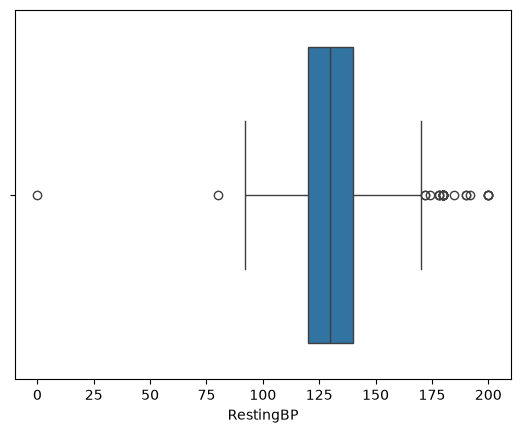

In [178]:
sns.boxplot(x=df['RestingBP'])

In [179]:
# RestingBP outlier remove
Q1=df.RestingBP.quantile(0.25)
Q3=df.RestingBP.quantile(0.75)
IQR=Q3-Q1
Lower_boundry=Q1-1.5*IQR
Upper_boundry=Q3+1.5*IQR
print(Lower_boundry,Upper_boundry)

90.0 170.0


In [180]:
df.RestingBP.median()

np.float64(130.0)

In [181]:
df.loc[df['RestingBP']>170,'RestingBP']=130

<Axes: xlabel='RestingBP'>

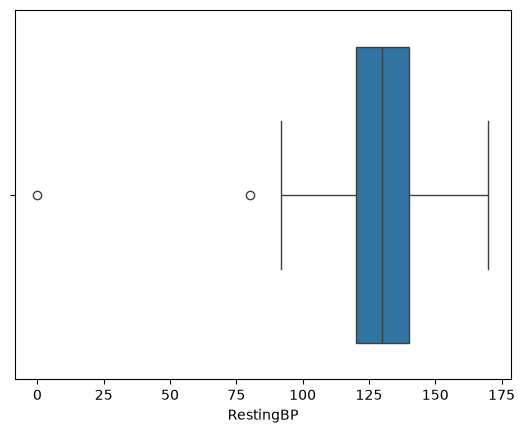

In [182]:
sns.boxplot(x=df.RestingBP)

<Axes: xlabel='Cholesterol'>

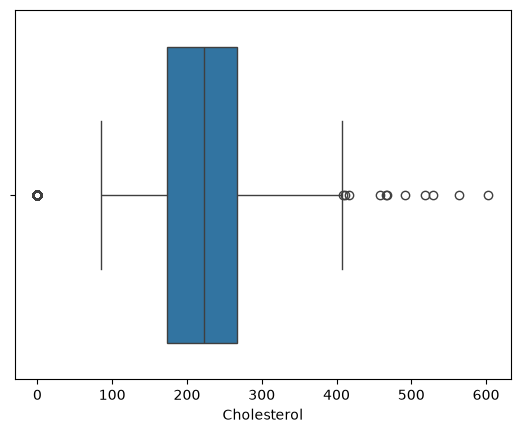

In [183]:
sns.boxplot(x=df.Cholesterol)

In [184]:
# Cholesterol outlier remove
Q1=df.Cholesterol.quantile(0.25)
Q3=df.Cholesterol.quantile(0.75)
IQR=Q3-Q1
Lower_boundry=Q1-1.5*IQR
Upper_boundry=Q3+1.5*IQR
print(Lower_boundry,Upper_boundry)

32.625 407.625


In [185]:
df.Cholesterol.median()

np.float64(223.0)

In [186]:
df.loc[df['Cholesterol']>407.625,'Cholesterol']=223

<Axes: xlabel='Cholesterol'>

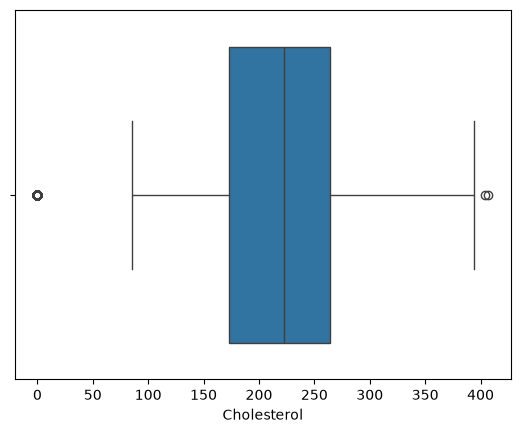

In [187]:
sns.boxplot(x=df.Cholesterol)

<Axes: xlabel='Oldpeak'>

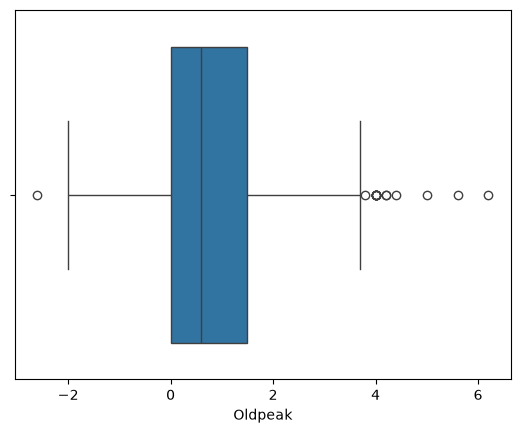

In [188]:
sns.boxplot(x=df.Oldpeak)

In [189]:
# Oldpeak column outlier remove
Q1=df.Oldpeak.quantile(0.25)
Q3=df.Oldpeak.quantile(0.75)
IQR=Q3-Q1
Lower_boundry=Q1-1.5*IQR
Upper_boundry=Q3+1.5*IQR
print(Lower_boundry,Upper_boundry)

-2.25 3.75


In [190]:
df.Oldpeak.median()

np.float64(0.6)

In [191]:
df.loc[df['Oldpeak']>3.75,'Oldpeak']=0.6

<Axes: xlabel='Oldpeak'>

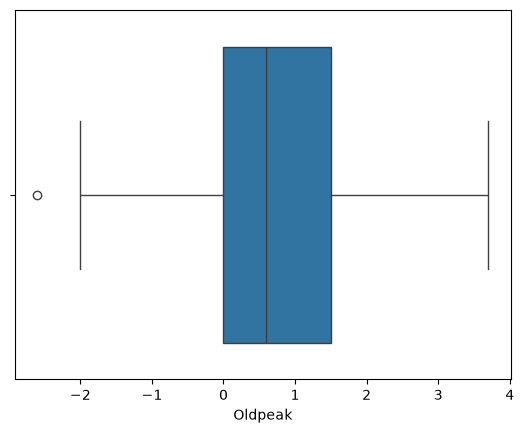

In [192]:
sns.boxplot(x=df.Oldpeak)

# 5. Feture selection

- Using heatmap to finding correlation

<Axes: >

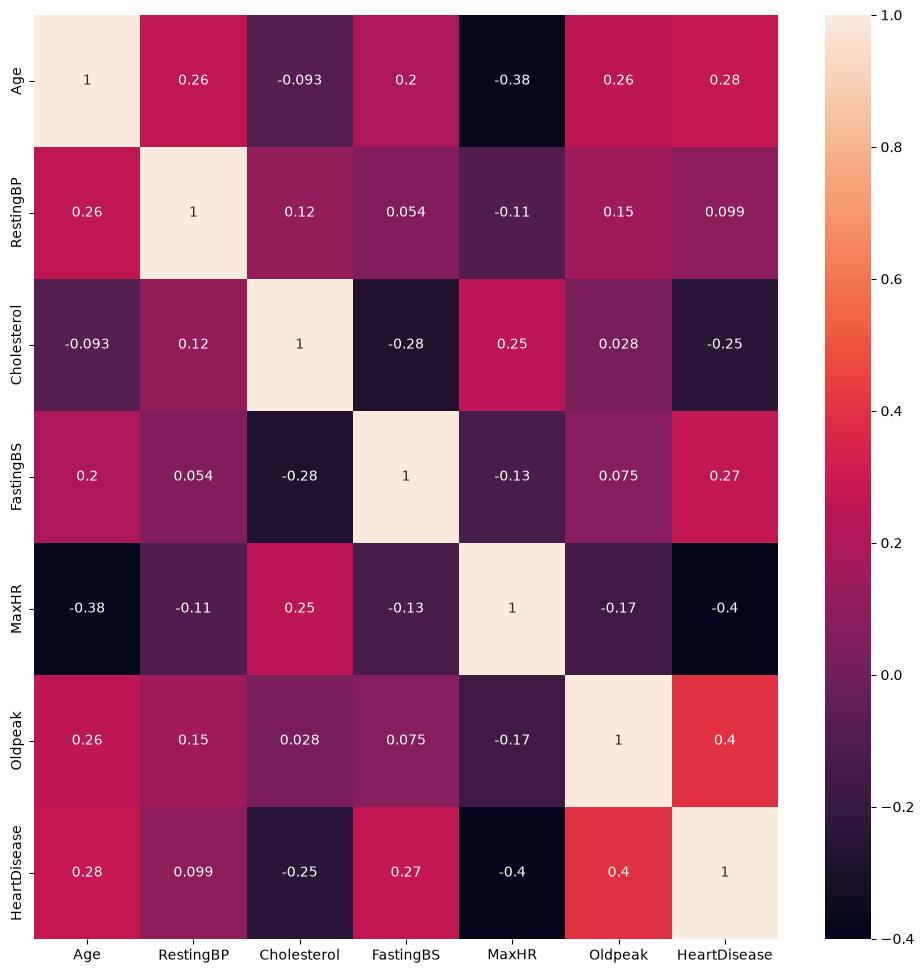

In [193]:
plt.figure(figsize=(12,12))
sns.heatmap(df[num_col].corr(),annot=True)

- Insights:
    - oldpeak and RestingBP is highly correlated so we can dorp any one column

# 6. preprocessing

- Encoding

In [194]:
cat_col

Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='str')

In [195]:
df.head(2)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1


In [196]:
df.Sex.value_counts()

Sex
M    725
F    193
Name: count, dtype: int64

- in the column we use onehot encoding

In [197]:
df.ChestPainType.value_counts()

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

- in this column we use onehot encoding

In [198]:
df.RestingECG.value_counts()

RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

- in this column we use onehot encoding

In [199]:
df.ExerciseAngina.value_counts()

ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

- in this column we use Leable encoding

In [200]:
df.ST_Slope.value_counts()

ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64

- in this column we use onehot encoding

### Create a preprocessing pipeline

In [201]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

- Leable Encoding:- ExerciseAngina
- OneHot Encoding:-Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
- Standard Scaler:- Age,RestingBP,Cholesterol,FastingBS,MaxHR

## Separate all columns based on type of preprocessing

In [202]:
OHE_column=['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope']
Standard_Scaler=['Age','RestingBP','Cholesterol','FastingBS','MaxHR']
Lable_encoder=['ExerciseAngina']
passthrough=[]

In [203]:
# modified Lable encoder
class ModifiedLabelEncoder(LabelEncoder):
    def fit_transform(self, y, *args, **kwargs):
        return super().fit_transform(y).reshape(-1, 1)

    def transform(self, y, *args, **kwargs):
        return super().transform(y).reshape(-1, 1)

In [204]:
def same(x):
    return x

In [205]:
# no transformation with few columns will be the same 
no_trans=FunctionTransformer(same)

In [206]:
perprocessor=ColumnTransformer([('One Hot Encoder',OneHotEncoder(),OHE_column),
                               ('ModifiedLableEncoder',ModifiedLabelEncoder(),Lable_encoder),
                               ('Standard Scaler',StandardScaler(),Standard_Scaler),
                               ('pass_through',no_trans,passthrough)])

In [207]:
perprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('One Hot Encoder', ...), ('ModifiedLableEncoder', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``trans

In [208]:
# create the pickel file for preprocessor
import pickle

In [209]:
file=open('Preprocessed_heart_diseas.pkl','wb')
pickle.dump(perprocessor,file)
print('pickel file has been created')

pickel file has been created
